In [76]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [77]:
print(df.shape)
df.info()


(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

In [78]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print(df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())

df[df["TotalCharges"].isna()][["customerID", "tenure", "TotalCharges"]]

float64
Missing values: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,NaN
753,3115-CZMZD,0,NaN
936,5709-LVOEQ,0,NaN
1082,4367-NUYAO,0,NaN
1340,1371-DWPAZ,0,NaN
3331,7644-OMVMY,0,NaN
3826,3213-VVOLG,0,NaN
4380,2520-SGTTA,0,NaN
5218,2923-ARZLG,0,NaN
6670,4075-WKNIU,0,NaN


In [79]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print("Missing values left:", df["TotalCharges"].isna().sum())
print("Churn rate:", round(df["ChurnFlag"].mean() * 100, 1), "%")
df[["Churn", "ChurnFlag"]].head()


Missing values left: 0
Churn rate: 26.5 %


,Churn,ChurnFlag
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


In [80]:
contract = df.groupby("Contract")["ChurnFlag"].agg(["count", "mean"])
contract["churn_pct"] = (contract["mean"] * 100).round(1)
contract = contract.rename(columns={"count": "customers"})
contract[["customers", "churn_pct"]].sort_values("churn_pct", ascending=False)

,customers,churn_pct
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


In [81]:
df["tenure_bucket"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 mo", "13-24 mo", "25-48 mo", "49-72 mo"]
)

tenure = df.groupby("tenure_bucket", observed=True)["ChurnFlag"].agg(["count", "mean"])
tenure["churn_pct"] = (tenure["mean"] * 100).round(1)
tenure[["count", "churn_pct"]]

,count,churn_pct
tenure_bucket,,
0-12 mo,2186,47.4
13-24 mo,1024,28.7
25-48 mo,1594,20.4
49-72 mo,2239,9.5


In [82]:
combo = df.groupby(["Contract", "tenure_bucket"], observed=True)["ChurnFlag"].agg(["count", "mean"])
combo["churn_pct"] = (combo["mean"] * 100).round(1)
combo[["count", "churn_pct"]]

count  churn_pct
Contract       tenure_bucket                  
Month-to-month 0-12 mo         1994       51.4
               13-24 mo         737       37.7
               25-48 mo         802       32.9
               49-72 mo         342       26.0
One year       0-12 mo          124       10.5
               13-24 mo         197        8.1
               25-48 mo         518       10.6
               49-72 mo         634       12.9
Two year       0-12 mo           68        0.0
               13-24 mo          90        0.0
               25-48 mo         274        2.2
               49-72 mo        1263        3.3

In [83]:
for col in ["InternetService", "PaymentMethod"]:
    result = df.groupby(col)["ChurnFlag"].agg(["count", "mean"])
    result["churn_pct"] = (result["mean"] * 100).round(1)
    print(result[["count", "churn_pct"]].sort_values("churn_pct", ascending=False))
    print()

                 count  churn_pct
InternetService                  
Fiber optic       3096       41.9
DSL               2421       19.0
No                1526        7.4

                           count  churn_pct
PaymentMethod                              
Electronic check            2365       45.3
Mailed check                1612       19.1
Bank transfer (automatic)   1544       16.7
Credit card (automatic)     1522       15.2



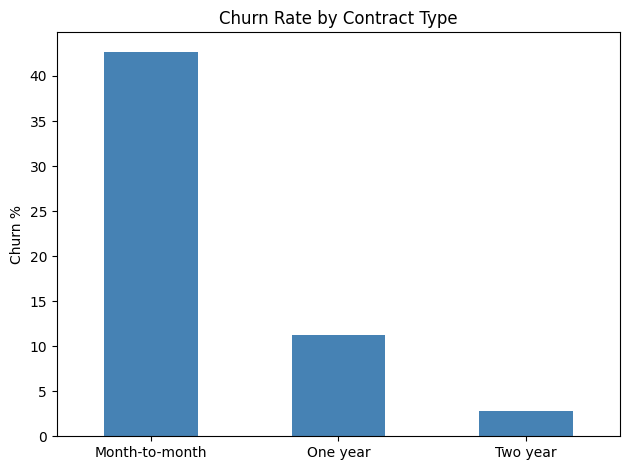

In [84]:
import matplotlib.pyplot as plt

churn_by_contract = df.groupby("Contract")["ChurnFlag"].mean() * 100

churn_by_contract.plot(kind="bar", color="steelblue")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn %")
plt.xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("churn_by_contract.png", dpi=150)
plt.show()

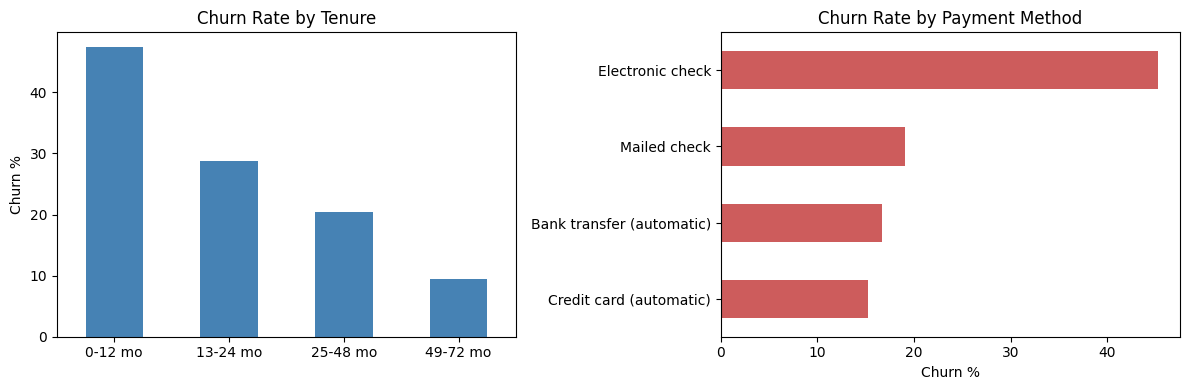

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

tenure_churn = df.groupby("tenure_bucket", observed=True)["ChurnFlag"].mean() * 100
tenure_churn.plot(kind="bar", color="steelblue", ax=axes[0])
axes[0].set_title("Churn Rate by Tenure")
axes[0].set_ylabel("Churn %")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)

pay_churn = df.groupby("PaymentMethod")["ChurnFlag"].mean().sort_values() * 100
pay_churn.plot(kind="barh", color="indianred", ax=axes[1])
axes[1].set_title("Churn Rate by Payment Method")
axes[1].set_xlabel("Churn %")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("churn_tenure_payment.png", dpi=150)
plt.show()

In [86]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

X = pd.get_dummies(df.drop(columns=["customerID", "Churn", "ChurnFlag", "tenure_bucket"]), drop_first=True)
y = df["ChurnFlag"]

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

num = ["tenure", "MonthlyCharges", "TotalCharges"]
mu, sd = Xtr[num].mean(), Xtr[num].std()
Xtr[num] = (Xtr[num] - mu) / sd
Xte[num] = (Xte[num] - mu) / sd

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(Xtr.astype(float), ytr)

print(classification_report(yte, model.predict(Xte.astype(float))))

coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()
print("Lower churn:\n", coefs.head(5))
print("\nHigher churn:\n", coefs.tail(5))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Lower churn:
 Contract_Two year   -1.412808
tenure              -1.155590
Contract_One year   -0.717230
MonthlyCharges      -0.535600
PhoneService_Yes    -0.347979
dtype: float64

Higher churn:
 StreamingTV_Yes                   0.392280
PaymentMethod_Electronic check    0.403814
StreamingMovies_Yes               0.417526
TotalCharges                      0.486289
InternetService_Fiber optic       1.210582
dtype: float64


In [87]:
df.to_csv("telco_clean.csv", index=False)
print("Saved!", df.shape)

Saved! (7043, 23)
